# **MODELO DE REGRESIÓN**

*El presente modelo Genera una señal coseno con ruido gaussiano x(t) y una señal objetivo o(t) sin ruido a tarvés de un modelo de regresión con una Red Neuronal.*

Importación de librerias

In [1]:
import numpy as np # Manejo de vectores y matrices
import tensorflow as tf # Para el procesamiento de tensores y redes neuronales
import matplotlib.pyplot as plt # Generación de gráficas de señales y error
from IPython.display import clear_output, display # Control de visualización en la consola
from tensorflow.keras.models import Sequential # Estructura para crear el modelo capa por capa
from tensorflow.keras.layers import Input, SimpleRNN, Dense # Capas de Entrada, Recurrente (Memoria) y Densa (Salida)
from tensorflow.keras.optimizers import Adam # Algoritmo para optimizar el aprendizaje del modelo
from sklearn.metrics import mean_squared_error, mean_absolute_error # Métricas MSE y MAE para la etapa de Prueba

Datos de entrada y señal objetivo

In [2]:
# Número total de pasos para generar la señal
num_steps = 2500

# Rango de entrada (0 a 2499)
n = np.arange(0, num_steps)

# Para graficar un ciclo completo de la señal de entrada
o_t = np.cos(100 * np.pi * n / num_steps) # Señal objetivo

# Señal de entrada x(t)
noise = np.random.normal(0, 0.2, num_steps)
x_t = o_t + noise


Graficación de señal de entrada y señal objetivo

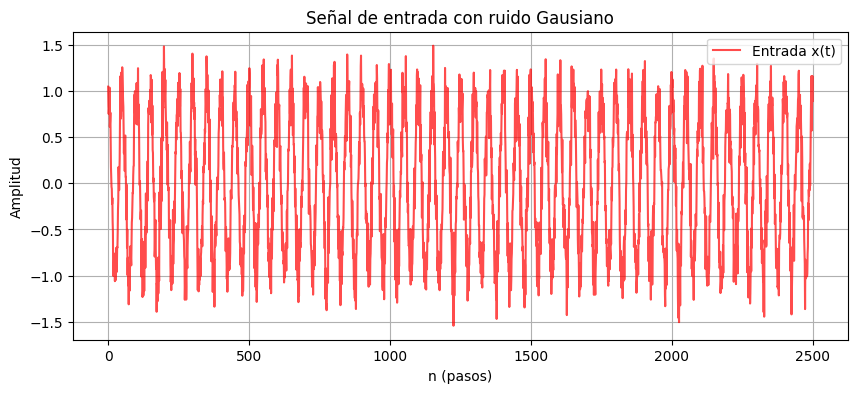

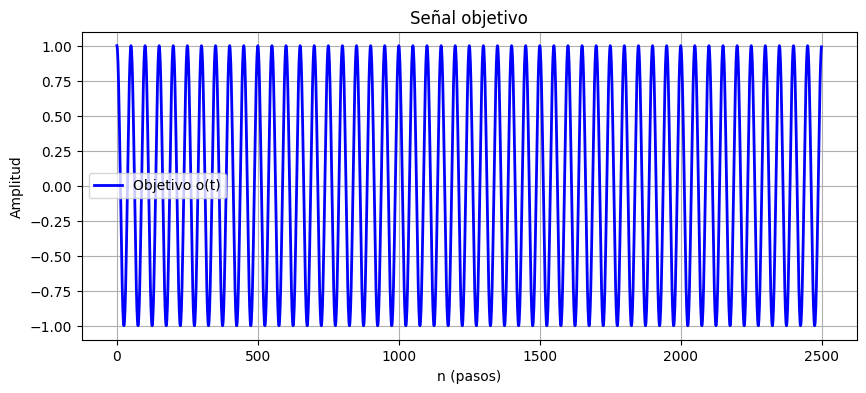

In [3]:
# Señal de entrada
plt.figure(figsize=(10, 4))
plt.plot(n, x_t, color='red', alpha=0.7, label="Entrada x(t)")
plt.title("Señal de entrada con ruido Gausiano")
plt.xlabel("n (pasos)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)
plt.show()

# Señal objetivo
plt.figure(figsize=(10, 4))
plt.plot(n, o_t, color='blue', linewidth=2, label="Objetivo o(t)")
plt.title("Señal objetivo")
plt.xlabel("n (pasos)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)
plt.show()

Red neuronal de Elman (generar, imprimir parámetros y compilar)

In [4]:
# Red de Elman (SimpleRNN)
model = Sequential([
    Input(shape=(1, 1), batch_size=1),
    SimpleRNN(units=32, activation='tanh', stateful=True),
    Dense(1)
])

# Imprimir modelo
print(model.summary())

# Compilar
model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='mse',
    metrics=['mae']
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (1, 32)                │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (1, 1)                 │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

None


Preparar para entrenar y correr

In [5]:
x_list, d_list, y_list, e_list = [], [], [], []
mae_post_list = [] # guarda el MAE acumulado desde 1500
abs_err_post_list = [] # guarda |e(n)| desde 1500
mae_post_value = None # MAE final post-1500

mse_post_list = [] # guarda el MSE acumulado desde 1500
sq_err_post_list = []
mse_post_value = None # MSE final post-1500

Correr y entrenar

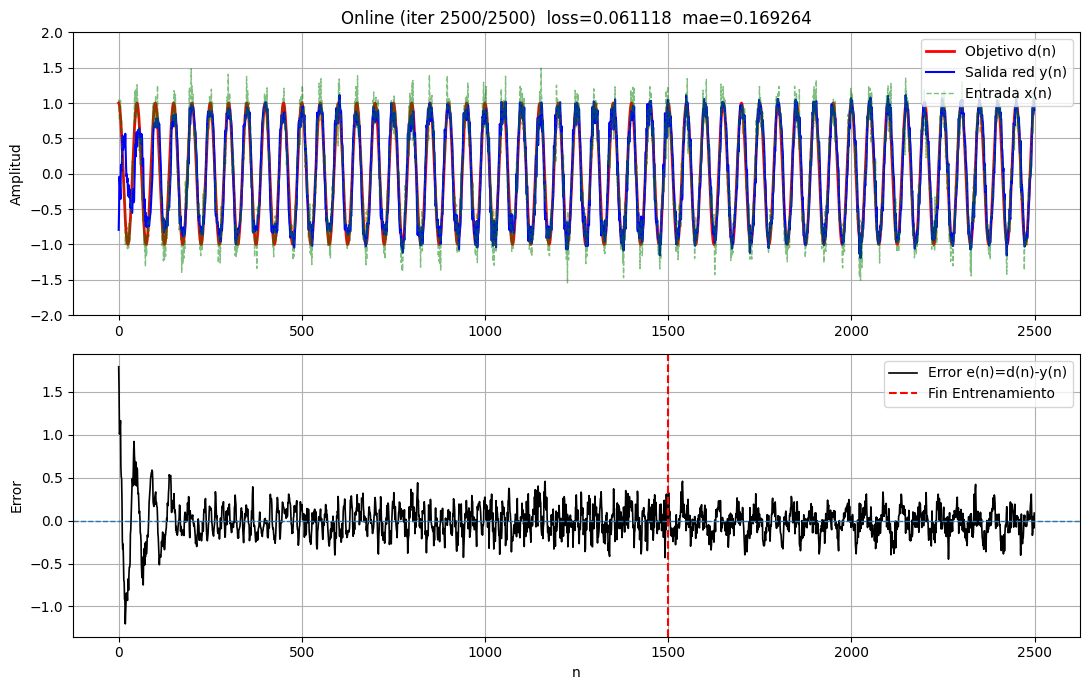

In [6]:
for k in range(num_steps):
    # Usamos tus variables x_t y o_t
    x_val = x_t[k]
    d_val = o_t[k]


    x_in = np.array([[[x_val]]], dtype=np.float32)   # (1,1,1)
    d_in = np.array([[d_val]], dtype=np.float32)     # (1,1)

    # ENTRENAR (solo antes de la iteración 1500)
    if k < 1500:
        loss, mae = model.train_on_batch(x_in, d_in)

    # PREDECIR
    y_out = model.predict_on_batch(x_in)
    y_val = float(y_out[0, 0])

    # ERROR
    e_val = float(d_val - y_val)

    # GUARDAR
    x_list.append(float(x_val))
    d_list.append(float(d_val))
    y_list.append(y_val)
    e_list.append(e_val)

    # -------- MÉTRICAS post-1500 --------
    if k >= 1500:
        error_absoluto = abs(e_val)
        error_cuadratico = e_val ** 2

        abs_err_post_list.append(error_absoluto)
        sq_err_post_list.append(error_cuadratico)

        # Calcular promedios acumulados en el momento 'k'
        mae_post_list.append(np.mean(abs_err_post_list))
        mse_post_list.append(np.mean(sq_err_post_list))

    # -------- gráfica online --------
    if (k % 20 == 0) or (k == num_steps - 1):
        clear_output(wait=True)
        pasos = np.arange(len(y_list))

        plt.figure(figsize=(11, 7))

        # Subplot 1: señales
        plt.subplot(2, 1, 1)
        plt.plot(pasos, d_list, 'r-', linewidth=2, label='Objetivo d(n)')
        plt.plot(pasos, y_list, 'b-', linewidth=1.5, label='Salida red y(n)')
        plt.plot(pasos, x_list, 'g--', linewidth=1, alpha=0.5, label='Entrada x(n)')
        plt.title(f'Online (iter {k+1}/{num_steps})  loss={loss:.6f}  mae={mae:.6f}')
        plt.ylabel('Amplitud')
        plt.ylim(-2.0, 2.0)
        plt.grid(True)
        plt.legend(loc='upper right')

        # Subplot 2: error
        plt.subplot(2, 1, 2)
        plt.plot(pasos, e_list, 'k-', linewidth=1.2, label='Error e(n)=d(n)-y(n)')
        plt.axhline(0, linestyle='--', linewidth=1)
        if k >= 1500:
            plt.axvline(x=1500, color='r', linestyle='--', label='Fin Entrenamiento')

        plt.xlabel('n')
        plt.ylabel('Error')
        plt.grid(True)
        plt.legend(loc='upper right')

        plt.tight_layout()
        plt.show()

Graficar MAE y MSE

MAE después de n=1500: 0.113706
MSE después de n=1500: 0.021007


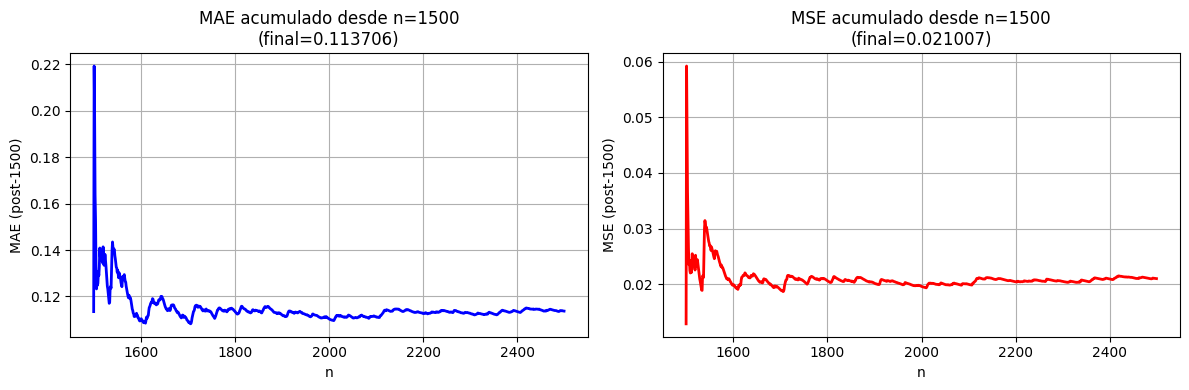

In [7]:
# Calcular los valores finales
mae_post_value = float(np.mean(abs_err_post_list))
mse_post_value = float(np.mean(sq_err_post_list))
print(f"MAE después de n=1500: {mae_post_value:.6f}")
print(f"MSE después de n=1500: {mse_post_value:.6f}")

plt.figure(figsize=(12, 4))

# --- Gráfica 1: MAE ---
plt.subplot(1, 2, 1)
plt.plot(np.arange(1500, num_steps), mae_post_list, linewidth=2, color='blue')
plt.title(f"MAE acumulado desde n=1500\n(final={mae_post_value:.6f})")
plt.xlabel("n")
plt.ylabel("MAE (post-1500)")
plt.grid(True)

# --- Gráfica 2: MSE ---
plt.subplot(1, 2, 2)
plt.plot(np.arange(1500, num_steps), mse_post_list, linewidth=2, color='red')
plt.title(f"MSE acumulado desde n=1500\n(final={mse_post_value:.6f})")
plt.xlabel("n")
plt.ylabel("MSE (post-1500)")
plt.grid(True)

# Ajustar el espacio y mostrar
plt.tight_layout()
plt.show()